In [1]:
# AML Transaction Risk Scoring System
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("AML project environment is ready!")

AML project environment is ready!


In [2]:
# Step 2: Create a synthetic AML transaction dataset

import pandas as pd
import numpy as np

# Make results reproducible
np.random.seed(42)

# Number of transactions
n = 5000

# Create synthetic transaction data
data = pd.DataFrame({
    "Transaction_ID": [f"TXN{i:06d}" for i in range(1, n + 1)],
    "Customer_ID": [f"CUST{np.random.randint(1000, 1999)}" for _ in range(n)],
    "Customer_Country": np.random.choice(
        ["UK", "Germany", "France", "India", "UAE", "Singapore",
         "Poland", "Lithuania", "Latvia", "Nigeria"],
        size=n
    ),
    "Transaction_Type": np.random.choice(
        ["Bank Transfer", "Card Payment", "Cash Deposit", "Cash Withdrawal"],
        size=n
    ),
    "Transaction_Amount": np.round(
        np.random.lognormal(mean=7.5, sigma=1.2, size=n), 2
    ),
    "Account_Age_Days": np.random.randint(30, 3000, size=n),
    "PEP_Flag": np.random.choice([0, 1], size=n, p=[0.96, 0.04]),
    "Previous_Alerts": np.random.poisson(lam=0.4, size=n),
    "Transactions_Last_24h": np.random.randint(1, 20, size=n),
    "High_Risk_Country": np.random.choice([0, 1], size=n, p=[0.90, 0.10]),
})

# Display the first 10 transactions
data.head(10)

,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Account_Age_Days,PEP_Flag,Previous_Alerts,Transactions_Last_24h,High_Risk_Country
0,TXN000001,CUST1102,Lithuania,Bank Transfer,2960.72,1602,0,0,1,0
1,TXN000002,CUST1435,Poland,Card Payment,3404.13,1768,0,0,1,0
2,TXN000003,CUST1860,Singapore,Bank Transfer,2041.57,2035,0,2,2,0
3,TXN000004,CUST1270,Poland,Bank Transfer,92.35,833,0,0,12,0
4,TXN000005,CUST1106,UAE,Card Payment,249.06,2466,0,1,18,0
5,TXN000006,CUST1071,Poland,Bank Transfer,1357.34,2653,0,1,12,0
6,TXN000007,CUST1700,UK,Bank Transfer,990.53,2019,0,0,1,0
7,TXN000008,CUST1020,UK,Card Payment,1819.73,2709,1,1,11,0
8,TXN000009,CUST1614,Latvia,Cash Deposit,1029.39,2791,0,2,2,0
9,TXN000010,CUST1121,UAE,Card Payment,11361.33,1099,0,1,12,1


In [3]:
# Step 3: Basic AML data quality and profile checks

print("Dataset shape:")
print(data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

print("\nBasic statistics:")
display(data.describe())

Dataset shape:
(5000, 10)

Column names:
['Transaction_ID', 'Customer_ID', 'Customer_Country', 'Transaction_Type', 'Transaction_Amount', 'Account_Age_Days', 'PEP_Flag', 'Previous_Alerts', 'Transactions_Last_24h', 'High_Risk_Country']

Missing values:
Transaction_ID           0
Customer_ID              0
Customer_Country         0
Transaction_Type         0
Transaction_Amount       0
Account_Age_Days         0
PEP_Flag                 0
Previous_Alerts          0
Transactions_Last_24h    0
High_Risk_Country        0
dtype: int64

Basic statistics:


,Transaction_Amount,Account_Age_Days,PEP_Flag,Previous_Alerts,Transactions_Last_24h,High_Risk_Country
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3732.699456,1532.725600,0.041200,0.421800,9.922200,0.106200
std,6422.602976,851.520618,0.198772,0.642781,5.459094,0.308124
min,19.910000,30.000000,0.000000,0.000000,1.000000,0.000000
25%,790.120000,806.750000,0.000000,0.000000,5.000000,0.000000
50%,1783.930000,1542.000000,0.000000,0.000000,10.000000,0.000000
75%,4094.792500,2256.000000,0.000000,1.000000,15.000000,0.000000
max,127118.880000,2998.000000,1.000000,5.000000,19.000000,1.000000


In [4]:
# Step 4: Create initial AML risk indicators

data["High_Amount_Flag"] = np.where(
    data["Transaction_Amount"] > 10000, 1, 0
)

data["High_Frequency_Flag"] = np.where(
    data["Transactions_Last_24h"] > 15, 1, 0
)

data["Previous_Alert_Flag"] = np.where(
    data["Previous_Alerts"] > 0, 1, 0
)

# Display transactions that have at least one risk indicator
risk_indicators = data[
    (data["High_Amount_Flag"] == 1) |
    (data["High_Frequency_Flag"] == 1) |
    (data["PEP_Flag"] == 1) |
    (data["High_Risk_Country"] == 1) |
    (data["Previous_Alert_Flag"] == 1)
]

print("Total transactions:", len(data))
print("Transactions with at least one risk indicator:", len(risk_indicators))

display(risk_indicators.head(10))

Total transactions: 5000
Transactions with at least one risk indicator: 2945


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Account_Age_Days,PEP_Flag,Previous_Alerts,Transactions_Last_24h,High_Risk_Country,High_Amount_Flag,High_Frequency_Flag,Previous_Alert_Flag
2,TXN000003,CUST1860,Singapore,Bank Transfer,2041.57,2035,0,2,2,0,0,0,1
4,TXN000005,CUST1106,UAE,Card Payment,249.06,2466,0,1,18,0,0,1,1
5,TXN000006,CUST1071,Poland,Bank Transfer,1357.34,2653,0,1,12,0,0,0,1
7,TXN000008,CUST1020,UK,Card Payment,1819.73,2709,1,1,11,0,0,0,1
8,TXN000009,CUST1614,Latvia,Cash Deposit,1029.39,2791,0,2,2,0,0,0,1
9,TXN000010,CUST1121,UAE,Card Payment,11361.33,1099,0,1,12,1,1,0,1
11,TXN000012,CUST1214,France,Cash Withdrawal,2599.70,2699,1,0,17,0,0,1,0
13,TXN000014,CUST1458,France,Card Payment,4195.83,2801,1,0,16,0,0,1,0
14,TXN000015,CUST1087,Latvia,Cash Withdrawal,4650.49,569,0,1,19,0,0,1,1
16,TXN000017,CUST1099,Singapore,Bank Transfer,875.88,2880,0,1,7,0,0,0,1


In [5]:
# Step 5: Calculate AML Risk Score

data["Risk_Score"] = (
    data["High_Amount_Flag"] * 25 +
    data["High_Frequency_Flag"] * 20 +
    data["PEP_Flag"] * 25 +
    data["High_Risk_Country"] * 20 +
    data["Previous_Alert_Flag"] * 10
)

# Create risk categories
def classify_risk(score):
    if score >= 75:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 25:
        return "Medium"
    else:
        return "Low"

data["Risk_Category"] = data["Risk_Score"].apply(classify_risk)

# Display the most relevant AML fields
display(
    data[
        [
            "Transaction_ID",
            "Transaction_Amount",
            "PEP_Flag",
            "High_Risk_Country",
            "High_Amount_Flag",
            "High_Frequency_Flag",
            "Previous_Alert_Flag",
            "Risk_Score",
            "Risk_Category"
        ]
    ].head(20)
)

,Transaction_ID,Transaction_Amount,PEP_Flag,High_Risk_Country,High_Amount_Flag,High_Frequency_Flag,Previous_Alert_Flag,Risk_Score,Risk_Category
0,TXN000001,2960.72,0,0,0,0,0,0,Low
1,TXN000002,3404.13,0,0,0,0,0,0,Low
2,TXN000003,2041.57,0,0,0,0,1,10,Low
3,TXN000004,92.35,0,0,0,0,0,0,Low
4,TXN000005,249.06,0,0,0,1,1,30,Medium
5,TXN000006,1357.34,0,0,0,0,1,10,Low
6,TXN000007,990.53,0,0,0,0,0,0,Low
7,TXN000008,1819.73,1,0,0,0,1,35,Medium
8,TXN000009,1029.39,0,0,0,0,1,10,Low
9,TXN000010,11361.33,0,1,1,0,1,55,High


AML Risk Category Distribution:


,count
Risk_Category,
Low,3913
Medium,955
High,128
Critical,4


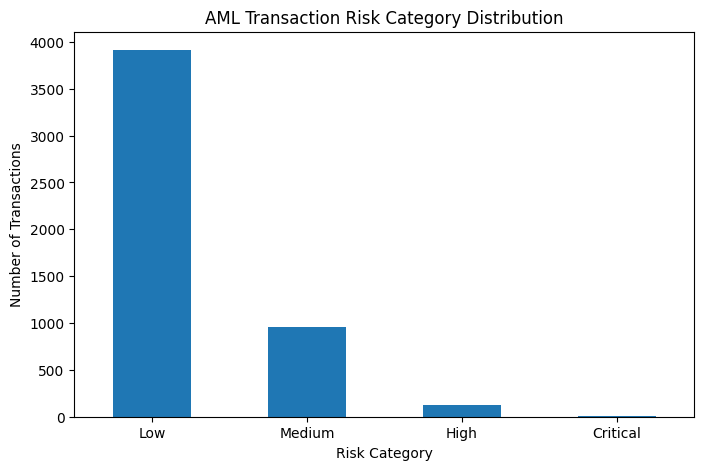

In [6]:
# Step 6: Analyze AML risk category distribution

risk_distribution = data["Risk_Category"].value_counts().reindex(
    ["Low", "Medium", "High", "Critical"],
    fill_value=0
)

print("AML Risk Category Distribution:")
display(risk_distribution)

# Create a bar chart
plt.figure(figsize=(8, 5))

risk_distribution.plot(kind="bar")

plt.title("AML Transaction Risk Category Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [7]:
# Step 7A: Identify High and Critical risk transactions

high_risk_transactions = data[
    data["Risk_Category"].isin(["High", "Critical"])
].copy()

print("High and Critical Risk Transactions:")
print("Total:", len(high_risk_transactions))

display(
    high_risk_transactions[
        [
            "Transaction_ID",
            "Customer_ID",
            "Customer_Country",
            "Transaction_Type",
            "Transaction_Amount",
            "PEP_Flag",
            "High_Risk_Country",
            "High_Amount_Flag",
            "High_Frequency_Flag",
            "Previous_Alert_Flag",
            "Risk_Score",
            "Risk_Category"
        ]
    ].sort_values(
        by="Risk_Score",
        ascending=False
    ).head(20)
)

High and Critical Risk Transactions:
Total: 132


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,PEP_Flag,High_Risk_Country,High_Amount_Flag,High_Frequency_Flag,Previous_Alert_Flag,Risk_Score,Risk_Category
2985,TXN002986,CUST1643,Poland,Bank Transfer,19597.04,1,0,1,1,1,80,Critical
4596,TXN004597,CUST1267,UAE,Cash Deposit,10040.39,0,1,1,1,1,75,Critical
1002,TXN001003,CUST1118,France,Cash Withdrawal,45098.79,0,1,1,1,1,75,Critical
3983,TXN003984,CUST1042,Latvia,Bank Transfer,36237.15,0,1,1,1,1,75,Critical
4315,TXN004316,CUST1507,UAE,Cash Withdrawal,24828.26,1,0,1,1,0,70,High
4553,TXN004554,CUST1935,Lithuania,Cash Withdrawal,12464.82,1,0,1,1,0,70,High
2545,TXN002546,CUST1317,Lithuania,Cash Deposit,21471.06,1,0,1,1,0,70,High
4241,TXN004242,CUST1441,UK,Cash Deposit,19608.00,1,1,1,0,0,70,High
3568,TXN003569,CUST1769,Germany,Cash Deposit,10875.39,1,0,1,1,0,70,High
2079,TXN002080,CUST1002,Singapore,Card Payment,16202.65,1,1,1,0,0,70,High


In [8]:
# Step 7B: Generate AML alert reasons

def generate_alert_reasons(row):
    reasons = []

    if row["PEP_Flag"] == 1:
        reasons.append("PEP")

    if row["High_Risk_Country"] == 1:
        reasons.append("High-Risk Country")

    if row["High_Amount_Flag"] == 1:
        reasons.append("High Transaction Amount")

    if row["High_Frequency_Flag"] == 1:
        reasons.append("High Transaction Frequency")

    if row["Previous_Alert_Flag"] == 1:
        reasons.append("Previous Alert")

    return " + ".join(reasons)


data["Alert_Reasons"] = data.apply(generate_alert_reasons, axis=1)

# Display High and Critical transactions with their alert reasons

display(
    data[
        data["Risk_Category"].isin(["High", "Critical"])
    ][
        [
            "Transaction_ID",
            "Customer_ID",
            "Transaction_Amount",
            "Risk_Score",
            "Risk_Category",
            "Alert_Reasons"
        ]
    ].sort_values(
        by="Risk_Score",
        ascending=False
    ).head(20)
)

,Transaction_ID,Customer_ID,Transaction_Amount,Risk_Score,Risk_Category,Alert_Reasons
2985,TXN002986,CUST1643,19597.04,80,Critical,PEP + High Transaction Amount + High Transacti...
4596,TXN004597,CUST1267,10040.39,75,Critical,High-Risk Country + High Transaction Amount + ...
1002,TXN001003,CUST1118,45098.79,75,Critical,High-Risk Country + High Transaction Amount + ...
3983,TXN003984,CUST1042,36237.15,75,Critical,High-Risk Country + High Transaction Amount + ...
4315,TXN004316,CUST1507,24828.26,70,High,PEP + High Transaction Amount + High Transacti...
4553,TXN004554,CUST1935,12464.82,70,High,PEP + High Transaction Amount + High Transacti...
2545,TXN002546,CUST1317,21471.06,70,High,PEP + High Transaction Amount + High Transacti...
4241,TXN004242,CUST1441,19608.00,70,High,PEP + High-Risk Country + High Transaction Amount
3568,TXN003569,CUST1769,10875.39,70,High,PEP + High Transaction Amount + High Transacti...
2079,TXN002080,CUST1002,16202.65,70,High,PEP + High-Risk Country + High Transaction Amount


In [ ]:
data.loc[
    data["Transaction_ID"] == "TXN002986",
    ["Transaction_ID", "Risk_Score", "Risk_Category", "Alert_Reasons"]
]

,Transaction_ID,Risk_Score,Risk_Category,Alert_Reasons
2985,TXN002986,80,Critical,PEP + High Transaction Amount + High Transacti...


In [9]:
# Step 8A: Create AML investigation recommendations

def investigation_action(category):
    if category == "Critical":
        return "Priority Investigation"
    elif category == "High":
        return "Enhanced Review"
    elif category == "Medium":
        return "Analyst Review"
    else:
        return "Routine Monitoring"


data["Investigation_Action"] = data["Risk_Category"].apply(
    investigation_action
)

# Display the results for High and Critical transactions

display(
    data[
        data["Risk_Category"].isin(["High", "Critical"])
    ][
        [
            "Transaction_ID",
            "Customer_ID",
            "Risk_Score",
            "Risk_Category",
            "Alert_Reasons",
            "Investigation_Action"
        ]
    ].sort_values(
        by="Risk_Score",
        ascending=False
    ).head(20)
)

,Transaction_ID,Customer_ID,Risk_Score,Risk_Category,Alert_Reasons,Investigation_Action
2985,TXN002986,CUST1643,80,Critical,PEP + High Transaction Amount + High Transacti...,Priority Investigation
4596,TXN004597,CUST1267,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
1002,TXN001003,CUST1118,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
3983,TXN003984,CUST1042,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
4315,TXN004316,CUST1507,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
4553,TXN004554,CUST1935,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
2545,TXN002546,CUST1317,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
4241,TXN004242,CUST1441,70,High,PEP + High-Risk Country + High Transaction Amount,Enhanced Review
3568,TXN003569,CUST1769,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
2079,TXN002080,CUST1002,70,High,PEP + High-Risk Country + High Transaction Amount,Enhanced Review


In [10]:
# Step 8B: Create AML Alert Queue

alert_queue = data[
    data["Risk_Category"].isin(["High", "Critical"])
].copy()

# Select the most important investigation fields
alert_queue = alert_queue[
    [
        "Transaction_ID",
        "Customer_ID",
        "Customer_Country",
        "Transaction_Type",
        "Transaction_Amount",
        "Risk_Score",
        "Risk_Category",
        "Alert_Reasons",
        "Investigation_Action"
    ]
]

# Sort by highest risk first
alert_queue = alert_queue.sort_values(
    by="Risk_Score",
    ascending=False
)

print("AML Alert Queue")
print("Total alerts:", len(alert_queue))

display(alert_queue.head(20))

AML Alert Queue
Total alerts: 132


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Risk_Score,Risk_Category,Alert_Reasons,Investigation_Action
2985,TXN002986,CUST1643,Poland,Bank Transfer,19597.04,80,Critical,PEP + High Transaction Amount + High Transacti...,Priority Investigation
4596,TXN004597,CUST1267,UAE,Cash Deposit,10040.39,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
1002,TXN001003,CUST1118,France,Cash Withdrawal,45098.79,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
3983,TXN003984,CUST1042,Latvia,Bank Transfer,36237.15,75,Critical,High-Risk Country + High Transaction Amount + ...,Priority Investigation
4315,TXN004316,CUST1507,UAE,Cash Withdrawal,24828.26,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
4553,TXN004554,CUST1935,Lithuania,Cash Withdrawal,12464.82,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
2545,TXN002546,CUST1317,Lithuania,Cash Deposit,21471.06,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
4241,TXN004242,CUST1441,UK,Cash Deposit,19608.00,70,High,PEP + High-Risk Country + High Transaction Amount,Enhanced Review
3568,TXN003569,CUST1769,Germany,Cash Deposit,10875.39,70,High,PEP + High Transaction Amount + High Transacti...,Enhanced Review
2079,TXN002080,CUST1002,Singapore,Card Payment,16202.65,70,High,PEP + High-Risk Country + High Transaction Amount,Enhanced Review


In [11]:
# Step 9A: Create customer-level AML risk summary

customer_summary = data.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "count"),
    Total_Transaction_Value=("Transaction_Amount", "sum"),
    Average_Transaction_Amount=("Transaction_Amount", "mean"),
    Maximum_Risk_Score=("Risk_Score", "max"),
    Total_PEP_Flags=("PEP_Flag", "sum"),
    Total_High_Risk_Country_Flags=("High_Risk_Country", "sum"),
    Total_High_Amount_Flags=("High_Amount_Flag", "sum"),
    Total_High_Frequency_Flags=("High_Frequency_Flag", "sum"),
    Total_Previous_Alerts=("Previous_Alert_Flag", "sum")
).reset_index()

# Sort customers by maximum transaction risk
customer_summary = customer_summary.sort_values(
    by="Maximum_Risk_Score",
    ascending=False
)

print("Customer-level AML Risk Summary")
print("Total customers:", len(customer_summary))

display(customer_summary.head(20))

Customer-level AML Risk Summary
Total customers: 988


,Customer_ID,Total_Transactions,Total_Transaction_Value,Average_Transaction_Amount,Maximum_Risk_Score,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_High_Amount_Flags,Total_High_Frequency_Flags,Total_Previous_Alerts
637,CUST1643,3,22300.13,7433.376667,80,1,0,1,2,1
42,CUST1042,6,68169.69,11361.615000,75,1,2,2,2,2
116,CUST1118,6,73023.39,12170.565000,75,0,2,2,4,3
264,CUST1267,11,24960.97,2269.179091,75,1,1,1,3,2
759,CUST1769,7,32877.59,4696.798571,70,1,0,2,2,0
313,CUST1317,10,133689.39,13368.939000,70,2,0,2,5,5
436,CUST1441,6,60638.02,10106.336667,70,2,4,2,4,2
924,CUST1935,12,64113.19,5342.765833,70,1,1,2,3,3
502,CUST1507,6,35946.57,5991.095000,70,1,0,1,2,4
2,CUST1002,4,23575.35,5893.837500,70,1,1,1,0,0


In [12]:
# Step 9B: Calculate customer-level AML risk score

customer_summary["Customer_Risk_Score"] = (
    customer_summary["Maximum_Risk_Score"]
    + customer_summary["Total_PEP_Flags"] * 5
    + customer_summary["Total_High_Risk_Country_Flags"] * 5
    + customer_summary["Total_Previous_Alerts"] * 3
)

# Cap the score at 100
customer_summary["Customer_Risk_Score"] = (
    customer_summary["Customer_Risk_Score"].clip(upper=100)
)

# Create customer risk categories
def classify_customer_risk(score):
    if score >= 75:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 25:
        return "Medium"
    else:
        return "Low"

customer_summary["Customer_Risk_Category"] = (
    customer_summary["Customer_Risk_Score"]
    .apply(classify_customer_risk)
)

# Display the highest-risk customers
display(
    customer_summary[
        [
            "Customer_ID",
            "Total_Transactions",
            "Total_Transaction_Value",
            "Maximum_Risk_Score",
            "Total_PEP_Flags",
            "Total_High_Risk_Country_Flags",
            "Total_Previous_Alerts",
            "Customer_Risk_Score",
            "Customer_Risk_Category"
        ]
    ].sort_values(
        by="Customer_Risk_Score",
        ascending=False
    ).head(20)
)

,Customer_ID,Total_Transactions,Total_Transaction_Value,Maximum_Risk_Score,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_Previous_Alerts,Customer_Risk_Score,Customer_Risk_Category
436,CUST1441,6,60638.02,70,2,4,2,100,Critical
42,CUST1042,6,68169.69,75,1,2,2,96,Critical
313,CUST1317,10,133689.39,70,2,0,5,95,Critical
116,CUST1118,6,73023.39,75,0,2,3,94,Critical
917,CUST1928,12,42959.75,55,1,3,6,93,Critical
264,CUST1267,11,24960.97,75,1,1,2,91,Critical
592,CUST1597,7,22043.72,65,1,3,2,91,Critical
924,CUST1935,12,64113.19,70,1,1,3,89,Critical
89,CUST1091,6,39236.80,60,2,2,3,89,Critical
909,CUST1920,10,23052.73,55,2,1,6,88,Critical


Customer Risk Category Distribution:


,count
Customer_Risk_Category,
Low,214
Medium,491
High,245
Critical,38


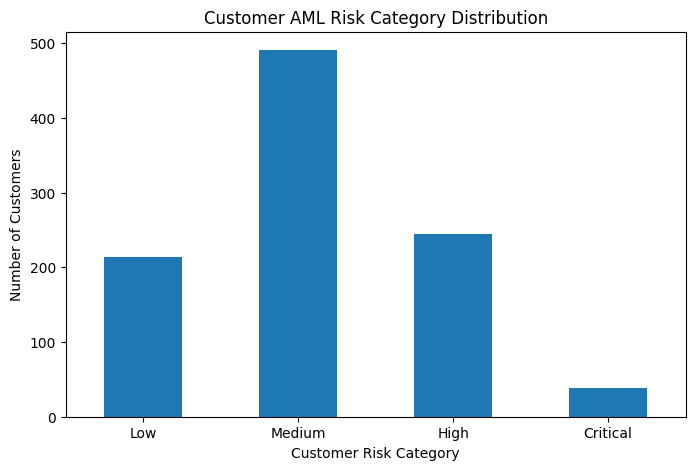

In [13]:
# Step 9C: Customer risk category distribution

customer_risk_distribution = (
    customer_summary["Customer_Risk_Category"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High", "Critical"],
        fill_value=0
    )
)

print("Customer Risk Category Distribution:")
display(customer_risk_distribution)

# Create a bar chart
plt.figure(figsize=(8, 5))

customer_risk_distribution.plot(kind="bar")

plt.title("Customer AML Risk Category Distribution")
plt.xlabel("Customer Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

In [14]:
# Step 10A: Identify customers with high transaction velocity

velocity_analysis = data.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "count"),
    Maximum_Transactions_24h=("Transactions_Last_24h", "max"),
    Average_Transactions_24h=("Transactions_Last_24h", "mean"),
    Total_Transaction_Value=("Transaction_Amount", "sum")
).reset_index()

# Flag customers with high transaction velocity
velocity_analysis["High_Velocity_Flag"] = np.where(
    velocity_analysis["Maximum_Transactions_24h"] > 15,
    1,
    0
)

high_velocity_customers = velocity_analysis[
    velocity_analysis["High_Velocity_Flag"] == 1
].sort_values(
    by="Maximum_Transactions_24h",
    ascending=False
)

print("Customers with high transaction velocity:", len(high_velocity_customers))

display(high_velocity_customers.head(20))

Customers with high transaction velocity: 636


,Customer_ID,Total_Transactions,Maximum_Transactions_24h,Average_Transactions_24h,Total_Transaction_Value,High_Velocity_Flag
983,CUST1994,5,19,13.400000,11311.11,1
982,CUST1993,6,19,11.166667,38455.64,1
981,CUST1992,6,19,9.000000,52018.92,1
3,CUST1003,2,19,15.000000,2054.01,1
980,CUST1991,3,19,10.666667,3214.68,1
955,CUST1966,2,19,16.000000,2199.82,1
943,CUST1954,8,19,11.000000,14734.86,1
940,CUST1951,6,19,14.333333,29034.97,1
937,CUST1948,4,19,14.500000,39869.87,1
936,CUST1947,4,19,8.000000,9771.06,1


In [15]:
# Step 10B: Identify customers with repeated high-value transactions

high_value_analysis = data.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "count"),
    High_Value_Transactions=("High_Amount_Flag", "sum"),
    Total_Transaction_Value=("Transaction_Amount", "sum"),
    Maximum_Transaction_Amount=("Transaction_Amount", "max"),
    Average_Transaction_Amount=("Transaction_Amount", "mean")
).reset_index()

# Flag customers with 2 or more high-value transactions
high_value_analysis["Repeated_High_Value_Flag"] = np.where(
    high_value_analysis["High_Value_Transactions"] >= 2,
    1,
    0
)

repeated_high_value_customers = high_value_analysis[
    high_value_analysis["Repeated_High_Value_Flag"] == 1
].sort_values(
    by="High_Value_Transactions",
    ascending=False
)

print(
    "Customers with repeated high-value transactions:",
    len(repeated_high_value_customers)
)

display(repeated_high_value_customers.head(20))

Customers with repeated high-value transactions: 60


,Customer_ID,Total_Transactions,High_Value_Transactions,Total_Transaction_Value,Maximum_Transaction_Amount,Average_Transaction_Amount,Repeated_High_Value_Flag
250,CUST1253,9,4,100668.91,39301.19,11185.434444,1
227,CUST1230,8,4,74081.00,22996.30,9260.125000,1
337,CUST1341,8,3,62168.91,23454.67,7771.113750,1
409,CUST1413,7,3,60036.06,22208.31,8576.580000,1
444,CUST1449,8,3,72127.45,27953.10,9015.931250,1
756,CUST1766,6,3,119066.91,73480.59,19844.485000,1
946,CUST1957,12,3,87016.23,33248.22,7251.352500,1
42,CUST1042,6,2,68169.69,36237.15,11361.615000,1
1,CUST1001,6,2,42564.78,19924.53,7094.130000,1
16,CUST1016,8,2,67371.67,40539.56,8421.458750,1


In [16]:
# Step 10C: Identify customers with activity across multiple countries

country_analysis = data.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "count"),
    Unique_Countries=("Customer_Country", "nunique"),
    Total_Transaction_Value=("Transaction_Amount", "sum"),
    Maximum_Risk_Score=("Risk_Score", "max")
).reset_index()

# Flag customers with activity across 3 or more countries
country_analysis["Multiple_Country_Flag"] = np.where(
    country_analysis["Unique_Countries"] >= 3,
    1,
    0
)

multiple_country_customers = country_analysis[
    country_analysis["Multiple_Country_Flag"] == 1
].sort_values(
    by="Unique_Countries",
    ascending=False
)

print(
    "Customers with activity across 3 or more countries:",
    len(multiple_country_customers)
)

display(multiple_country_customers.head(20))

Customers with activity across 3 or more countries: 801


,Customer_ID,Total_Transactions,Unique_Countries,Total_Transaction_Value,Maximum_Risk_Score,Multiple_Country_Flag
664,CUST1671,10,8,32550.13,35,1
652,CUST1658,11,8,31364.01,30,1
946,CUST1957,12,8,87016.23,45,1
657,CUST1663,14,8,45441.40,55,1
943,CUST1954,8,8,14734.86,30,1
96,CUST1098,12,8,30879.96,30,1
730,CUST1738,8,8,15590.46,45,1
641,CUST1647,11,8,24701.03,40,1
11,CUST1011,10,8,33516.53,35,1
470,CUST1475,11,8,31657.98,45,1


In [17]:
# Step 10D: Identify customers with repeated cash transactions

cash_data = data[
    data["Transaction_Type"].isin(
        ["Cash Deposit", "Cash Withdrawal"]
    )
]

cash_analysis = cash_data.groupby("Customer_ID").agg(
    Total_Cash_Transactions=("Transaction_ID", "count"),
    Total_Cash_Value=("Transaction_Amount", "sum"),
    Maximum_Cash_Transaction=("Transaction_Amount", "max"),
    Average_Cash_Transaction=("Transaction_Amount", "mean")
).reset_index()

# Flag customers with 3 or more cash transactions
cash_analysis["Repeated_Cash_Activity_Flag"] = np.where(
    cash_analysis["Total_Cash_Transactions"] >= 3,
    1,
    0
)

repeated_cash_customers = cash_analysis[
    cash_analysis["Repeated_Cash_Activity_Flag"] == 1
].sort_values(
    by="Total_Cash_Transactions",
    ascending=False
)

print(
    "Customers with 3 or more cash transactions:",
    len(repeated_cash_customers)
)

display(repeated_cash_customers.head(20))

Customers with 3 or more cash transactions: 433


,Customer_ID,Total_Cash_Transactions,Total_Cash_Value,Maximum_Cash_Transaction,Average_Cash_Transaction,Repeated_Cash_Activity_Flag
609,CUST1665,9,25805.82,9900.78,2867.313333,1
592,CUST1647,9,22262.28,5156.82,2473.586667,1
616,CUST1675,9,41506.50,24782.25,4611.833333,1
243,CUST1267,8,23226.50,10040.39,2903.312500,1
230,CUST1252,8,24384.54,8595.65,3048.067500,1
769,CUST1839,7,14192.65,5733.99,2027.521429,1
309,CUST1343,7,12352.25,4606.21,1764.607143,1
432,CUST1475,7,14394.71,7635.73,2056.387143,1
291,CUST1323,7,45321.46,35198.21,6474.494286,1
327,CUST1364,7,21817.14,7260.85,3116.734286,1


In [18]:
# Step 10E: Build a customer investigation profile

investigation_profile = customer_summary[
    [
        "Customer_ID",
        "Total_Transactions",
        "Total_Transaction_Value",
        "Maximum_Risk_Score",
        "Total_PEP_Flags",
        "Total_High_Risk_Country_Flags",
        "Total_Previous_Alerts",
        "Customer_Risk_Score",
        "Customer_Risk_Category"
    ]
].copy()

# Add behavioural indicators
investigation_profile = investigation_profile.merge(
    velocity_analysis[
        [
            "Customer_ID",
            "Maximum_Transactions_24h",
            "High_Velocity_Flag"
        ]
    ],
    on="Customer_ID",
    how="left"
)

investigation_profile = investigation_profile.merge(
    high_value_analysis[
        [
            "Customer_ID",
            "High_Value_Transactions",
            "Repeated_High_Value_Flag"
        ]
    ],
    on="Customer_ID",
    how="left"
)

investigation_profile = investigation_profile.merge(
    country_analysis[
        [
            "Customer_ID",
            "Unique_Countries",
            "Multiple_Country_Flag"
        ]
    ],
    on="Customer_ID",
    how="left"
)

investigation_profile = investigation_profile.merge(
    cash_analysis[
        [
            "Customer_ID",
            "Total_Cash_Transactions",
            "Total_Cash_Value",
            "Repeated_Cash_Activity_Flag"
        ]
    ],
    on="Customer_ID",
    how="left"
)

# Customers without cash activity will have missing values
investigation_profile[
    [
        "Total_Cash_Transactions",
        "Total_Cash_Value",
        "Repeated_Cash_Activity_Flag"
    ]
] = investigation_profile[
    [
        "Total_Cash_Transactions",
        "Total_Cash_Value",
        "Repeated_Cash_Activity_Flag"
    ]
].fillna(0)

print("Customer Investigation Profile")
print("Total customers:", len(investigation_profile))

display(
    investigation_profile.sort_values(
        by="Customer_Risk_Score",
        ascending=False
    ).head(20)
)

Customer Investigation Profile
Total customers: 988


,Customer_ID,Total_Transactions,Total_Transaction_Value,Maximum_Risk_Score,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_Previous_Alerts,Customer_Risk_Score,Customer_Risk_Category,Maximum_Transactions_24h,High_Velocity_Flag,High_Value_Transactions,Repeated_High_Value_Flag,Unique_Countries,Multiple_Country_Flag,Total_Cash_Transactions,Total_Cash_Value,Repeated_Cash_Activity_Flag
6,CUST1441,6,60638.02,70,2,4,2,100,Critical,18,1,2,1,4,1,3.0,21845.50,1.0
1,CUST1042,6,68169.69,75,1,2,2,96,Critical,19,1,2,1,4,1,2.0,10012.68,0.0
5,CUST1317,10,133689.39,70,2,0,5,95,Critical,19,1,2,1,7,1,5.0,28999.88,1.0
2,CUST1118,6,73023.39,75,0,2,3,94,Critical,19,1,2,1,3,1,3.0,46235.50,1.0
38,CUST1928,12,42959.75,55,1,3,6,93,Critical,19,1,1,0,6,1,6.0,22588.65,1.0
3,CUST1267,11,24960.97,75,1,1,2,91,Critical,19,1,1,0,7,1,8.0,23226.50,1.0
12,CUST1597,7,22043.72,65,1,3,2,91,Critical,19,1,0,0,5,1,6.0,18760.17,1.0
7,CUST1935,12,64113.19,70,1,1,3,89,Critical,19,1,2,1,7,1,5.0,40960.49,1.0
19,CUST1091,6,39236.80,60,2,2,3,89,Critical,14,0,2,1,5,1,5.0,36106.08,1.0
41,CUST1920,10,23052.73,55,2,1,6,88,Critical,19,1,0,0,6,1,4.0,2237.19,1.0


In [19]:
# Step 10F: Calculate investigation priority

investigation_profile["Behavioural_Indicator_Count"] = (
    investigation_profile["High_Velocity_Flag"]
    + investigation_profile["Repeated_High_Value_Flag"]
    + investigation_profile["Multiple_Country_Flag"]
    + investigation_profile["Repeated_Cash_Activity_Flag"]
)

def assign_investigation_priority(row):
    if (
        row["Customer_Risk_Category"] == "Critical"
        and row["Behavioural_Indicator_Count"] >= 2
    ):
        return "Priority 1"

    elif (
        row["Customer_Risk_Category"] in ["Critical", "High"]
        and row["Behavioural_Indicator_Count"] >= 1
    ):
        return "Priority 2"

    elif row["Customer_Risk_Category"] in ["High", "Medium"]:
        return "Priority 3"

    else:
        return "Routine"

investigation_profile["Investigation_Priority"] = (
    investigation_profile.apply(
        assign_investigation_priority,
        axis=1
    )
)

print("Investigation Priority Distribution:")

priority_distribution = (
    investigation_profile["Investigation_Priority"]
    .value_counts()
    .reindex(
        ["Priority 1", "Priority 2", "Priority 3", "Routine"],
        fill_value=0
    )
)

display(priority_distribution)

print("\nTop Priority Customers:")

display(
    investigation_profile[
        investigation_profile["Investigation_Priority"] == "Priority 1"
    ].sort_values(
        by="Customer_Risk_Score",
        ascending=False
    ).head(20)
)

Investigation Priority Distribution:


,count
Investigation_Priority,
Priority 1,33
Priority 2,242
Priority 3,499
Routine,214



Top Priority Customers:


,Customer_ID,Total_Transactions,Total_Transaction_Value,Maximum_Risk_Score,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_Previous_Alerts,Customer_Risk_Score,Customer_Risk_Category,Maximum_Transactions_24h,High_Velocity_Flag,High_Value_Transactions,Repeated_High_Value_Flag,Unique_Countries,Multiple_Country_Flag,Total_Cash_Transactions,Total_Cash_Value,Repeated_Cash_Activity_Flag,Behavioural_Indicator_Count,Investigation_Priority
6,CUST1441,6,60638.02,70,2,4,2,100,Critical,18,1,2,1,4,1,3.0,21845.50,1.0,4.0,Priority 1
1,CUST1042,6,68169.69,75,1,2,2,96,Critical,19,1,2,1,4,1,2.0,10012.68,0.0,3.0,Priority 1
5,CUST1317,10,133689.39,70,2,0,5,95,Critical,19,1,2,1,7,1,5.0,28999.88,1.0,4.0,Priority 1
2,CUST1118,6,73023.39,75,0,2,3,94,Critical,19,1,2,1,3,1,3.0,46235.50,1.0,4.0,Priority 1
38,CUST1928,12,42959.75,55,1,3,6,93,Critical,19,1,1,0,6,1,6.0,22588.65,1.0,3.0,Priority 1
12,CUST1597,7,22043.72,65,1,3,2,91,Critical,19,1,0,0,5,1,6.0,18760.17,1.0,3.0,Priority 1
3,CUST1267,11,24960.97,75,1,1,2,91,Critical,19,1,1,0,7,1,8.0,23226.50,1.0,3.0,Priority 1
7,CUST1935,12,64113.19,70,1,1,3,89,Critical,19,1,2,1,7,1,5.0,40960.49,1.0,4.0,Priority 1
19,CUST1091,6,39236.80,60,2,2,3,89,Critical,14,0,2,1,5,1,5.0,36106.08,1.0,3.0,Priority 1
0,CUST1643,3,22300.13,80,1,0,1,88,Critical,19,1,1,0,3,1,0.0,0.00,0.0,2.0,Priority 1


In [20]:
# Step 11: Create AML Investigation Case Queue

case_queue = investigation_profile.copy()

# Create synthetic case IDs
case_queue["Case_ID"] = [
    f"CASE{i:05d}"
    for i in range(1, len(case_queue) + 1)
]

# Generate investigation focus

def generate_investigation_focus(row):
    focus = []

    if row["High_Velocity_Flag"] == 1:
        focus.append("Transaction Velocity")

    if row["Repeated_High_Value_Flag"] == 1:
        focus.append("Repeated High-Value Activity")

    if row["Multiple_Country_Flag"] == 1:
        focus.append("Multiple-Country Activity")

    if row["Repeated_Cash_Activity_Flag"] == 1:
        focus.append("Repeated Cash Activity")

    if row["Total_PEP_Flags"] > 0:
        focus.append("PEP Exposure")

    if row["Total_High_Risk_Country_Flags"] > 0:
        focus.append("High-Risk Country Exposure")

    if row["Total_Previous_Alerts"] > 0:
        focus.append("Previous Alerts")

    return " | ".join(focus)

case_queue["Investigation_Focus"] = case_queue.apply(
    generate_investigation_focus,
    axis=1
)

# Sort by investigation priority and customer risk score

priority_order = {
    "Priority 1": 1,
    "Priority 2": 2,
    "Priority 3": 3,
    "Routine": 4
}

case_queue["Priority_Order"] = case_queue[
    "Investigation_Priority"
].map(priority_order)

case_queue = case_queue.sort_values(
    by=["Priority_Order", "Customer_Risk_Score"],
    ascending=[True, False]
)

# Select columns for the analyst case queue

case_queue = case_queue[
    [
        "Case_ID",
        "Customer_ID",
        "Customer_Risk_Score",
        "Customer_Risk_Category",
        "Investigation_Priority",
        "Total_Transactions",
        "Total_Transaction_Value",
        "Behavioural_Indicator_Count",
        "Investigation_Focus"
    ]
]

print("AML Investigation Case Queue")
print("Total cases:", len(case_queue))

display(case_queue.head(20))

AML Investigation Case Queue
Total cases: 988


,Case_ID,Customer_ID,Customer_Risk_Score,Customer_Risk_Category,Investigation_Priority,Total_Transactions,Total_Transaction_Value,Behavioural_Indicator_Count,Investigation_Focus
6,CASE00007,CUST1441,100,Critical,Priority 1,6,60638.02,4.0,Transaction Velocity | Repeated High-Value Act...
1,CASE00002,CUST1042,96,Critical,Priority 1,6,68169.69,3.0,Transaction Velocity | Repeated High-Value Act...
5,CASE00006,CUST1317,95,Critical,Priority 1,10,133689.39,4.0,Transaction Velocity | Repeated High-Value Act...
2,CASE00003,CUST1118,94,Critical,Priority 1,6,73023.39,4.0,Transaction Velocity | Repeated High-Value Act...
38,CASE00039,CUST1928,93,Critical,Priority 1,12,42959.75,3.0,Transaction Velocity | Multiple-Country Activi...
3,CASE00004,CUST1267,91,Critical,Priority 1,11,24960.97,3.0,Transaction Velocity | Multiple-Country Activi...
12,CASE00013,CUST1597,91,Critical,Priority 1,7,22043.72,3.0,Transaction Velocity | Multiple-Country Activi...
7,CASE00008,CUST1935,89,Critical,Priority 1,12,64113.19,4.0,Transaction Velocity | Repeated High-Value Act...
19,CASE00020,CUST1091,89,Critical,Priority 1,6,39236.80,3.0,Repeated High-Value Activity | Multiple-Countr...
0,CASE00001,CUST1643,88,Critical,Priority 1,3,22300.13,2.0,Transaction Velocity | Multiple-Country Activi...


In [21]:
# Step 12: Add analyst review recommendations

def generate_review_recommendation(row):

    if row["Investigation_Priority"] == "Priority 1":
        return (
            "Priority investigation: review customer KYC profile, "
            "expected activity, transaction patterns, counterparties, "
            "source/purpose of funds, and previous alerts."
        )

    elif row["Investigation_Priority"] == "Priority 2":
        return (
            "Enhanced review: compare observed activity with the "
            "customer profile, expected activity and previous alerts."
        )

    elif row["Investigation_Priority"] == "Priority 3":
        return (
            "Analyst review: assess behavioural indicators and "
            "determine whether activity is consistent with the "
            "customer profile."
        )

    else:
        return (
            "Routine monitoring: no immediate priority indicators "
            "identified by the project rules."
        )


case_queue["Analyst_Review_Recommendation"] = case_queue.apply(
    generate_review_recommendation,
    axis=1
)

print("AML Case Queue with Analyst Recommendations")

display(
    case_queue.head(20)
)

AML Case Queue with Analyst Recommendations


,Case_ID,Customer_ID,Customer_Risk_Score,Customer_Risk_Category,Investigation_Priority,Total_Transactions,Total_Transaction_Value,Behavioural_Indicator_Count,Investigation_Focus,Analyst_Review_Recommendation
6,CASE00007,CUST1441,100,Critical,Priority 1,6,60638.02,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
1,CASE00002,CUST1042,96,Critical,Priority 1,6,68169.69,3.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
5,CASE00006,CUST1317,95,Critical,Priority 1,10,133689.39,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
2,CASE00003,CUST1118,94,Critical,Priority 1,6,73023.39,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
38,CASE00039,CUST1928,93,Critical,Priority 1,12,42959.75,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
3,CASE00004,CUST1267,91,Critical,Priority 1,11,24960.97,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
12,CASE00013,CUST1597,91,Critical,Priority 1,7,22043.72,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
7,CASE00008,CUST1935,89,Critical,Priority 1,12,64113.19,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
19,CASE00020,CUST1091,89,Critical,Priority 1,6,39236.80,3.0,Repeated High-Value Activity | Multiple-Countr...,Priority investigation: review customer KYC pr...
0,CASE00001,CUST1643,88,Critical,Priority 1,3,22300.13,2.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...


AML Risk Indicator Frequency:


,0
High Amount,396
High Frequency,1026
PEP,206
High-Risk Country,531
Previous Alert,1747


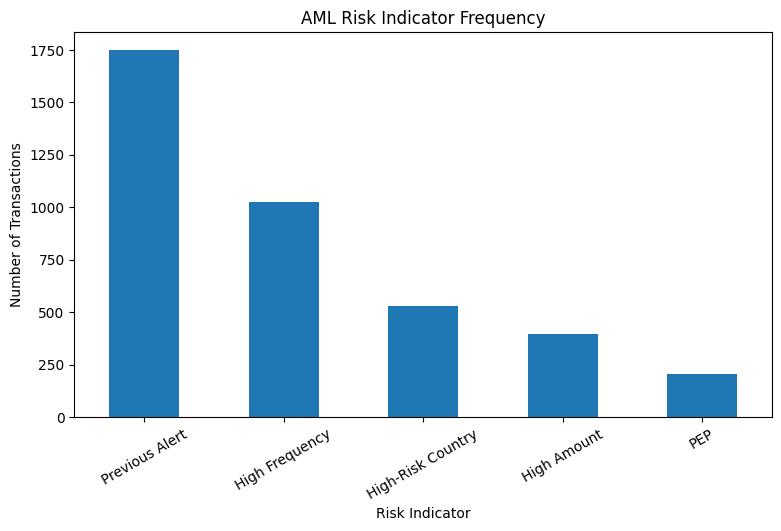

In [22]:
# Step 13: Analyze AML Risk Indicator Frequency

risk_indicator_counts = pd.Series({
    "High Amount": data["High_Amount_Flag"].sum(),
    "High Frequency": data["High_Frequency_Flag"].sum(),
    "PEP": data["PEP_Flag"].sum(),
    "High-Risk Country": data["High_Risk_Country"].sum(),
    "Previous Alert": data["Previous_Alert_Flag"].sum()
})

print("AML Risk Indicator Frequency:")
display(risk_indicator_counts)

plt.figure(figsize=(9, 5))

risk_indicator_counts.sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("AML Risk Indicator Frequency")
plt.xlabel("Risk Indicator")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.show()

Customer Risk Category Distribution:


,count
Customer_Risk_Category,
Low,214
Medium,491
High,245
Critical,38



Investigation Priority Distribution:


,count
Investigation_Priority,
Priority 1,33
Priority 2,242
Priority 3,499
Routine,214


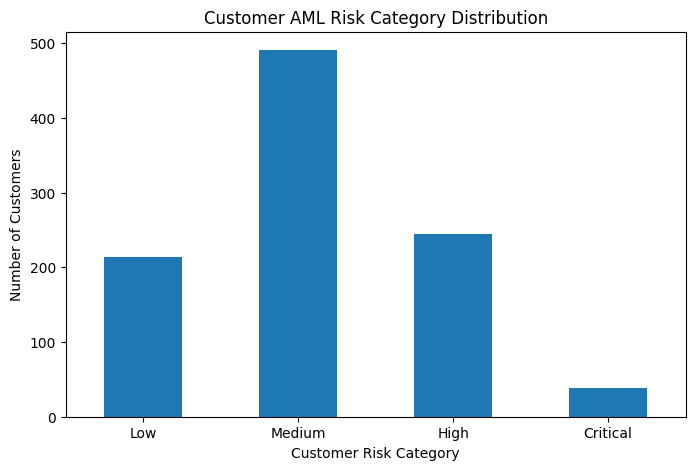

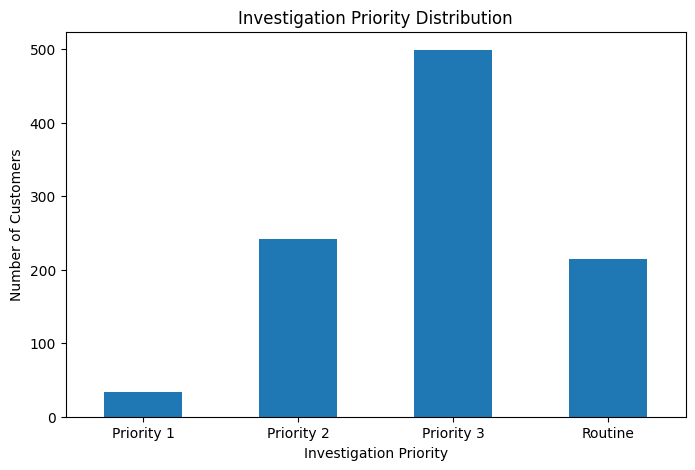

In [23]:
# Step 14: Analyze Customer Risk and Investigation Priority

print("Customer Risk Category Distribution:")

customer_risk_distribution = (
    investigation_profile["Customer_Risk_Category"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High", "Critical"],
        fill_value=0
    )
)

display(customer_risk_distribution)


print("\nInvestigation Priority Distribution:")

priority_distribution = (
    investigation_profile["Investigation_Priority"]
    .value_counts()
    .reindex(
        ["Priority 1", "Priority 2", "Priority 3", "Routine"],
        fill_value=0
    )
)

display(priority_distribution)


# Create customer risk chart

plt.figure(figsize=(8, 5))

customer_risk_distribution.plot(kind="bar")

plt.title("Customer AML Risk Category Distribution")
plt.xlabel("Customer Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()


# Create investigation priority chart

plt.figure(figsize=(8, 5))

priority_distribution.plot(kind="bar")

plt.title("Investigation Priority Distribution")
plt.xlabel("Investigation Priority")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

Customer Behavioural Risk Indicators:


,0
High Transaction Velocity,636.0
Repeated High-Value Activity,60.0
Multiple-Country Activity,801.0
Repeated Cash Activity,433.0


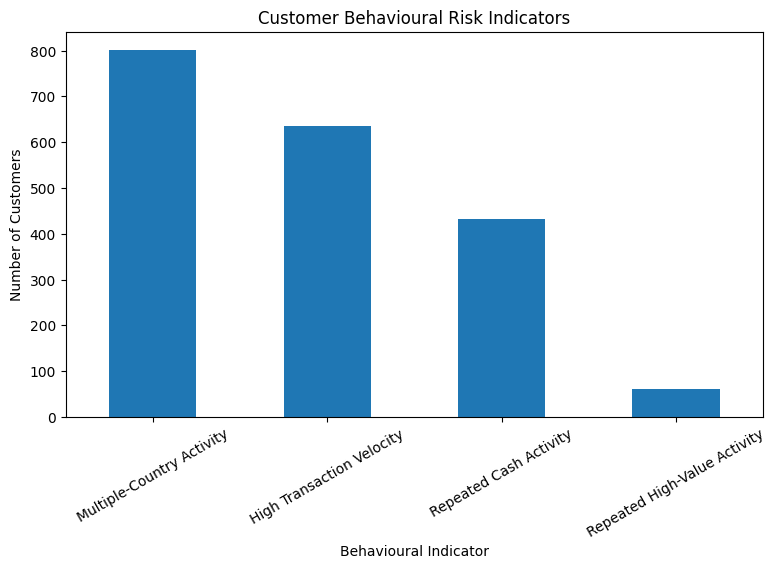

In [24]:
# Step 15: Analyze Customer Behavioural Risk Indicators

behavioural_indicator_counts = pd.Series({
    "High Transaction Velocity": investigation_profile["High_Velocity_Flag"].sum(),
    "Repeated High-Value Activity": investigation_profile["Repeated_High_Value_Flag"].sum(),
    "Multiple-Country Activity": investigation_profile["Multiple_Country_Flag"].sum(),
    "Repeated Cash Activity": investigation_profile["Repeated_Cash_Activity_Flag"].sum()
})

print("Customer Behavioural Risk Indicators:")
display(behavioural_indicator_counts)

plt.figure(figsize=(9, 5))

behavioural_indicator_counts.sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Customer Behavioural Risk Indicators")
plt.xlabel("Behavioural Indicator")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

In [25]:
# Step 16: Top Priority AML Investigation Cases

top_priority_cases = case_queue[
    case_queue["Investigation_Priority"] == "Priority 1"
].copy()

top_priority_cases = top_priority_cases.sort_values(
    by="Customer_Risk_Score",
    ascending=False
)

print("Top Priority AML Investigation Cases")
print("Priority 1 cases:", len(top_priority_cases))

display(
    top_priority_cases[
        [
            "Case_ID",
            "Customer_ID",
            "Customer_Risk_Score",
            "Customer_Risk_Category",
            "Investigation_Priority",
            "Total_Transactions",
            "Total_Transaction_Value",
            "Behavioural_Indicator_Count",
            "Investigation_Focus",
            "Analyst_Review_Recommendation"
        ]
    ].head(20)
)

Top Priority AML Investigation Cases
Priority 1 cases: 33


,Case_ID,Customer_ID,Customer_Risk_Score,Customer_Risk_Category,Investigation_Priority,Total_Transactions,Total_Transaction_Value,Behavioural_Indicator_Count,Investigation_Focus,Analyst_Review_Recommendation
6,CASE00007,CUST1441,100,Critical,Priority 1,6,60638.02,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
1,CASE00002,CUST1042,96,Critical,Priority 1,6,68169.69,3.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
5,CASE00006,CUST1317,95,Critical,Priority 1,10,133689.39,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
2,CASE00003,CUST1118,94,Critical,Priority 1,6,73023.39,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
38,CASE00039,CUST1928,93,Critical,Priority 1,12,42959.75,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
3,CASE00004,CUST1267,91,Critical,Priority 1,11,24960.97,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
12,CASE00013,CUST1597,91,Critical,Priority 1,7,22043.72,3.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...
7,CASE00008,CUST1935,89,Critical,Priority 1,12,64113.19,4.0,Transaction Velocity | Repeated High-Value Act...,Priority investigation: review customer KYC pr...
19,CASE00020,CUST1091,89,Critical,Priority 1,6,39236.80,3.0,Repeated High-Value Activity | Multiple-Countr...,Priority investigation: review customer KYC pr...
0,CASE00001,CUST1643,88,Critical,Priority 1,3,22300.13,2.0,Transaction Velocity | Multiple-Country Activi...,Priority investigation: review customer KYC pr...


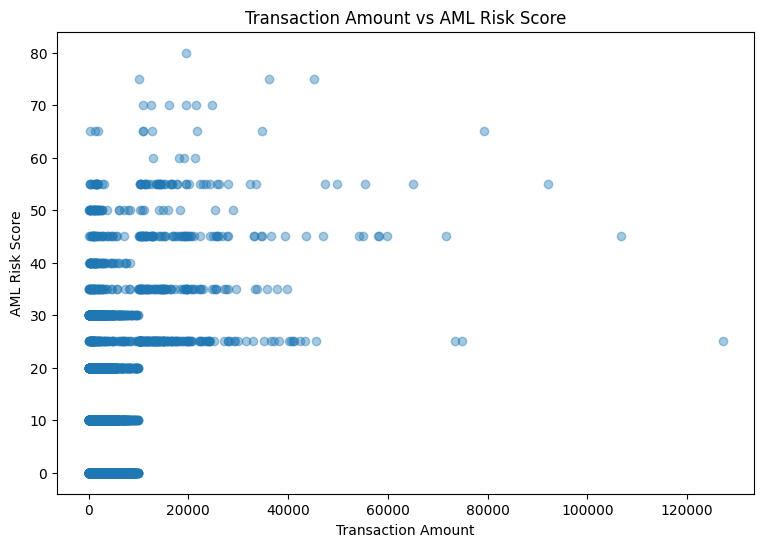

In [26]:
# Step 17: Analyze Transaction Amount vs AML Risk Score

plt.figure(figsize=(9, 6))

plt.scatter(
    data["Transaction_Amount"],
    data["Risk_Score"],
    alpha=0.4
)

plt.title("Transaction Amount vs AML Risk Score")
plt.xlabel("Transaction Amount")
plt.ylabel("AML Risk Score")

plt.show()

In [27]:
# Step 18: Create an improved synthetic AML dataset (Version 2)

np.random.seed(42)

n = 5000

# Create customers first
customer_ids = [
    f"CUST{i:04d}" for i in range(1000, 2000)
]

# Assign each customer a primary country
customer_primary_country = np.random.choice(
    [
        "UK", "Germany", "France", "India", "UAE",
        "Singapore", "Poland", "Lithuania", "Latvia", "Nigeria"
    ],
    size=len(customer_ids),
    p=[0.18, 0.12, 0.10, 0.20, 0.10,
       0.07, 0.08, 0.05, 0.05, 0.05]
)

customer_country_map = dict(
    zip(customer_ids, customer_primary_country)
)

# Assign behavioural profiles to customers
customer_profiles = np.random.choice(
    ["Normal", "Elevated", "High_Risk"],
    size=len(customer_ids),
    p=[0.75, 0.20, 0.05]
)

customer_profile_map = dict(
    zip(customer_ids, customer_profiles)
)

# Select customers for transactions
transaction_customers = np.random.choice(
    customer_ids,
    size=n,
    replace=True
)

data_v2 = pd.DataFrame({
    "Transaction_ID": [
        f"TXN{i:06d}" for i in range(1, n + 1)
    ],
    "Customer_ID": transaction_customers
})

# Generate country based on customer profile
def generate_country(customer_id):

    primary_country = customer_country_map[customer_id]
    profile = customer_profile_map[customer_id]

    if profile == "Normal":
        return primary_country

    elif profile == "Elevated":

        if np.random.random() < 0.80:
            return primary_country
        else:
            return np.random.choice([
                "UK", "Germany", "France", "India", "UAE",
                "Singapore", "Poland", "Lithuania", "Latvia", "Nigeria"
            ])

    else:
        return np.random.choice([
            "UK", "Germany", "France", "India", "UAE",
            "Singapore", "Poland", "Lithuania", "Latvia", "Nigeria"
        ])


data_v2["Customer_Country"] = [
    generate_country(customer_id)
    for customer_id in data_v2["Customer_ID"]
]

# Transaction type
data_v2["Transaction_Type"] = np.random.choice(
    [
        "Bank Transfer",
        "Card Payment",
        "Cash Deposit",
        "Cash Withdrawal"
    ],
    size=n,
    p=[0.45, 0.35, 0.10, 0.10]
)

# Transaction amount
data_v2["Transaction_Amount"] = np.round(
    np.random.lognormal(
        mean=7.3,
        sigma=1.0,
        size=n
    ),
    2
)

# Account age
data_v2["Account_Age_Days"] = np.random.randint(
    30,
    3000,
    size=n
)

# PEP exposure
data_v2["PEP_Flag"] = np.random.choice(
    [0, 1],
    size=n,
    p=[0.96, 0.04]
)

# Previous alerts
data_v2["Previous_Alerts"] = np.random.poisson(
    lam=0.25,
    size=n
)

# Transaction velocity
# Most transactions have normal velocity.
# A smaller number have elevated or high velocity.

velocity_group = np.random.choice(
    ["Normal", "Elevated", "High"],
    size=n,
    p=[0.85, 0.12, 0.03]
)

data_v2["Transactions_Last_24h"] = np.where(
    velocity_group == "Normal",
    np.random.randint(1, 9, size=n),
    np.where(
        velocity_group == "Elevated",
        np.random.randint(6, 16, size=n),
        np.random.randint(12, 26, size=n)
    )
)

# Synthetic high-risk country indicator
# This is a synthetic project flag, not a real-world country classification.
data_v2["High_Risk_Country"] = np.random.choice(
    [0, 1],
    size=n,
    p=[0.92, 0.08]
)

print("Improved synthetic AML dataset created!")
print("Rows:", len(data_v2))
print("Columns:", len(data_v2.columns))

display(data_v2.head(10))

Improved synthetic AML dataset created!
Rows: 5000
Columns: 10


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Account_Age_Days,PEP_Flag,Previous_Alerts,Transactions_Last_24h,High_Risk_Country
0,TXN000001,CUST1219,Poland,Bank Transfer,1842.20,1494,0,0,1,0
1,TXN000002,CUST1902,Nigeria,Cash Withdrawal,1252.86,1035,1,0,5,1
2,TXN000003,CUST1162,UAE,Card Payment,1462.65,2619,0,1,8,0
3,TXN000004,CUST1950,UAE,Bank Transfer,556.67,1664,0,0,4,0
4,TXN000005,CUST1219,Poland,Card Payment,331.21,123,0,0,5,0
5,TXN000006,CUST1269,Germany,Bank Transfer,3061.04,2073,0,0,8,0
6,TXN000007,CUST1631,Lithuania,Cash Withdrawal,2962.26,2976,0,0,7,0
7,TXN000008,CUST1905,Lithuania,Card Payment,7219.16,118,0,0,7,1
8,TXN000009,CUST1847,Nigeria,Bank Transfer,671.81,1983,0,0,9,0
9,TXN000010,CUST1399,Singapore,Card Payment,2959.62,2580,0,0,5,0


In [28]:
# Step 19: Validate the improved synthetic AML dataset

print("===== DATASET OVERVIEW =====")
print("Transactions:", len(data_v2))
print("Unique customers:", data_v2["Customer_ID"].nunique())

print("\n===== TRANSACTION AMOUNT =====")
display(
    data_v2["Transaction_Amount"].describe()
)

print("\n===== PEP DISTRIBUTION =====")
display(
    data_v2["PEP_Flag"].value_counts()
)

print("\n===== PREVIOUS ALERTS =====")
display(
    data_v2["Previous_Alerts"].value_counts().sort_index()
)

print("\n===== TRANSACTION VELOCITY =====")
display(
    data_v2["Transactions_Last_24h"].describe()
)

print("\n===== HIGH-RISK COUNTRY FLAG =====")
display(
    data_v2["High_Risk_Country"].value_counts()
)

print("\n===== TRANSACTION TYPES =====")
display(
    data_v2["Transaction_Type"].value_counts()
)

===== DATASET OVERVIEW =====
Transactions: 5000
Unique customers: 989

===== TRANSACTION AMOUNT =====


,Transaction_Amount
count,5000.000000
mean,2390.681686
std,3020.073560
min,29.300000
25%,767.595000
50%,1490.355000
75%,2840.797500
max,45656.920000



===== PEP DISTRIBUTION =====


,count
PEP_Flag,
0,4773
1,227



===== PREVIOUS ALERTS =====


...

,Transactions_Last_24h
count,5000.000000
mean,5.608200
std,3.780205
min,1.000000
25%,3.000000
50%,5.000000
75%,7.000000
max,25.000000



===== HIGH-RISK COUNTRY FLAG =====


,count
High_Risk_Country,
0,4615
1,385



===== TRANSACTION TYPES =====


,count
Transaction_Type,
Bank Transfer,2282
Card Payment,1751
Cash Deposit,492
Cash Withdrawal,475


In [29]:
# Step 20: Set Version 2 as the working AML dataset

# Keep Version 1 safely stored in 'data'
# Use Version 2 for the improved AML analysis

data_v1 = data.copy()

data = data_v2.copy()

print("AML working dataset updated successfully!")
print("Working dataset rows:", len(data))
print("Working dataset columns:", len(data.columns))
print("Unique customers:", data["Customer_ID"].nunique())

display(data.head(10))

AML working dataset updated successfully!
Working dataset rows: 5000
Working dataset columns: 10
Unique customers: 989


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Account_Age_Days,PEP_Flag,Previous_Alerts,Transactions_Last_24h,High_Risk_Country
0,TXN000001,CUST1219,Poland,Bank Transfer,1842.20,1494,0,0,1,0
1,TXN000002,CUST1902,Nigeria,Cash Withdrawal,1252.86,1035,1,0,5,1
2,TXN000003,CUST1162,UAE,Card Payment,1462.65,2619,0,1,8,0
3,TXN000004,CUST1950,UAE,Bank Transfer,556.67,1664,0,0,4,0
4,TXN000005,CUST1219,Poland,Card Payment,331.21,123,0,0,5,0
5,TXN000006,CUST1269,Germany,Bank Transfer,3061.04,2073,0,0,8,0
6,TXN000007,CUST1631,Lithuania,Cash Withdrawal,2962.26,2976,0,0,7,0
7,TXN000008,CUST1905,Lithuania,Card Payment,7219.16,118,0,0,7,1
8,TXN000009,CUST1847,Nigeria,Bank Transfer,671.81,1983,0,0,9,0
9,TXN000010,CUST1399,Singapore,Card Payment,2959.62,2580,0,0,5,0


In [30]:
# Step 21: Create AML Risk Indicators for Version 2

# High transaction amount
data["High_Amount_Flag"] = np.where(
    data["Transaction_Amount"] > 10000,
    1,
    0
)

# High transaction frequency
data["High_Frequency_Flag"] = np.where(
    data["Transactions_Last_24h"] > 15,
    1,
    0
)

# Previous alert indicator
data["Previous_Alert_Flag"] = np.where(
    data["Previous_Alerts"] > 0,
    1,
    0
)

# Identify transactions with at least one AML risk indicator
risk_indicators = data[
    (data["High_Amount_Flag"] == 1) |
    (data["High_Frequency_Flag"] == 1) |
    (data["PEP_Flag"] == 1) |
    (data["High_Risk_Country"] == 1) |
    (data["Previous_Alert_Flag"] == 1)
]

print("AML Risk Indicator Analysis")
print("----------------------------")
print("Total transactions:", len(data))
print(
    "Transactions with at least one risk indicator:",
    len(risk_indicators)
)
print(
    "Percentage with at least one indicator:",
    round(len(risk_indicators) / len(data) * 100, 2),
    "%"
)

display(
    risk_indicators[
        [
            "Transaction_ID",
            "Customer_ID",
            "Transaction_Amount",
            "PEP_Flag",
            "High_Risk_Country",
            "High_Amount_Flag",
            "High_Frequency_Flag",
            "Previous_Alert_Flag"
        ]
    ].head(10)
)

AML Risk Indicator Analysis
----------------------------
Total transactions: 5000
Transactions with at least one risk indicator: 1689
Percentage with at least one indicator: 33.78 %


,Transaction_ID,Customer_ID,Transaction_Amount,PEP_Flag,High_Risk_Country,High_Amount_Flag,High_Frequency_Flag,Previous_Alert_Flag
1,TXN000002,CUST1902,1252.86,1,1,0,0,0
2,TXN000003,CUST1162,1462.65,0,0,0,0,1
7,TXN000008,CUST1905,7219.16,0,1,0,0,0
11,TXN000012,CUST1990,4868.18,0,1,0,0,1
12,TXN000013,CUST1617,4113.23,0,0,0,0,1
17,TXN000018,CUST1840,746.62,0,0,0,0,1
18,TXN000019,CUST1812,392.37,1,0,0,0,0
19,TXN000020,CUST1227,1109.28,0,0,0,0,1
20,TXN000021,CUST1695,6737.30,0,0,0,0,1
21,TXN000022,CUST1618,4658.68,0,1,0,0,1


In [31]:
# Step 22: Calculate AML Risk Score for Version 2

data["Risk_Score"] = (
    data["High_Amount_Flag"] * 25
    + data["High_Frequency_Flag"] * 20
    + data["PEP_Flag"] * 25
    + data["High_Risk_Country"] * 20
    + data["Previous_Alert_Flag"] * 10
)

# Classify transactions by risk score
def classify_risk(score):
    if score >= 75:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 25:
        return "Medium"
    else:
        return "Low"

data["Risk_Category"] = data["Risk_Score"].apply(
    classify_risk
)

print("AML Risk Scoring Results")
print("------------------------")
print("Total transactions:", len(data))

display(
    data[
        [
            "Transaction_ID",
            "Customer_ID",
            "Transaction_Amount",
            "High_Amount_Flag",
            "High_Frequency_Flag",
            "PEP_Flag",
            "High_Risk_Country",
            "Previous_Alert_Flag",
            "Risk_Score",
            "Risk_Category"
        ]
    ].head(20)
)


AML Risk Scoring Results
------------------------
Total transactions: 5000


,Transaction_ID,Customer_ID,Transaction_Amount,High_Amount_Flag,High_Frequency_Flag,PEP_Flag,High_Risk_Country,Previous_Alert_Flag,Risk_Score,Risk_Category
0,TXN000001,CUST1219,1842.20,0,0,0,0,0,0,Low
1,TXN000002,CUST1902,1252.86,0,0,1,1,0,45,Medium
2,TXN000003,CUST1162,1462.65,0,0,0,0,1,10,Low
3,TXN000004,CUST1950,556.67,0,0,0,0,0,0,Low
4,TXN000005,CUST1219,331.21,0,0,0,0,0,0,Low
5,TXN000006,CUST1269,3061.04,0,0,0,0,0,0,Low
6,TXN000007,CUST1631,2962.26,0,0,0,0,0,0,Low
7,TXN000008,CUST1905,7219.16,0,0,0,1,0,20,Low
8,TXN000009,CUST1847,671.81,0,0,0,0,0,0,Low
9,TXN000010,CUST1399,2959.62,0,0,0,0,0,0,Low


AML Risk Category Distribution


,count
Risk_Category,
Low,4556
Medium,428
High,16
Critical,0



Percentage by Risk Category


,count
Risk_Category,
Low,91.12
Medium,8.56
High,0.32
Critical,0.00


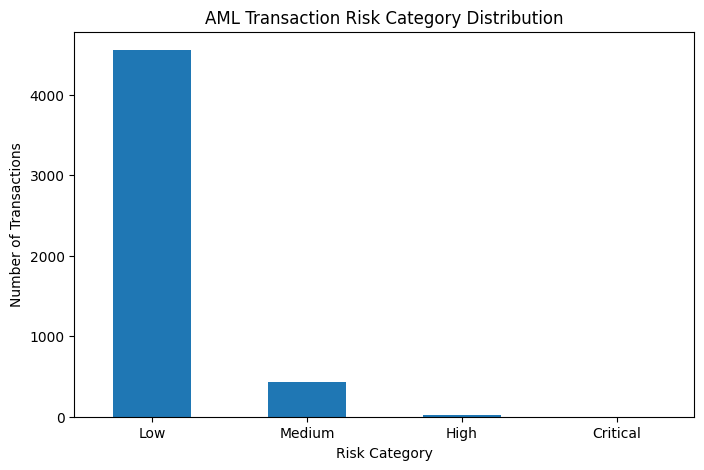

In [32]:
# Step 23: Analyze AML Risk Category Distribution

risk_distribution = (
    data["Risk_Category"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High", "Critical"],
        fill_value=0
    )
)

print("AML Risk Category Distribution")
display(risk_distribution)

print("\nPercentage by Risk Category")
display(
    (risk_distribution / len(data) * 100).round(2)
)

# Visualize the distribution
plt.figure(figsize=(8, 5))

risk_distribution.plot(kind="bar")

plt.title("AML Transaction Risk Category Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [33]:
# Step 24: Inspect the highest-scoring transactions

print("Highest AML Risk Scores:")
print("Maximum score:", data["Risk_Score"].max())

display(
    data.sort_values(
        by="Risk_Score",
        ascending=False
    )[
        [
            "Transaction_ID",
            "Customer_ID",
            "Transaction_Country"
            if "Transaction_Country" in data.columns
            else "Customer_Country",
            "Transaction_Amount",
            "PEP_Flag",
            "High_Risk_Country",
            "High_Amount_Flag",
            "High_Frequency_Flag",
            "Previous_Alert_Flag",
            "Risk_Score",
            "Risk_Category"
        ]
    ].head(20)
)

Highest AML Risk Scores:
Maximum score: 65


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Amount,PEP_Flag,High_Risk_Country,High_Amount_Flag,High_Frequency_Flag,Previous_Alert_Flag,Risk_Score,Risk_Category
132,TXN000133,CUST1531,Nigeria,11513.17,0,1,1,1,0,65,High
1246,TXN001247,CUST1532,Nigeria,2580.51,1,1,0,1,0,65,High
620,TXN000621,CUST1583,France,1585.90,1,1,0,1,0,65,High
1427,TXN001428,CUST1601,Germany,10782.46,1,0,1,0,1,60,High
3573,TXN003574,CUST1773,Nigeria,10119.55,1,0,1,0,1,60,High
2157,TXN002158,CUST1270,Poland,11008.34,1,0,1,0,1,60,High
1015,TXN001016,CUST1680,Poland,16343.47,0,0,1,1,1,55,High
4076,TXN004077,CUST1236,UK,4780.38,1,1,0,0,1,55,High
1190,TXN001191,CUST1888,UK,14848.24,0,1,1,0,1,55,High
2726,TXN002727,CUST1076,Poland,43380.63,1,0,1,0,0,50,High


In [34]:
# Step 25: Generate AML Alert Reasons

def generate_alert_reasons(row):
    reasons = []

    if row["PEP_Flag"] == 1:
        reasons.append("PEP Indicator")

    if row["High_Risk_Country"] == 1:
        reasons.append("Synthetic High-Risk Country Flag")

    if row["High_Amount_Flag"] == 1:
        reasons.append("High Transaction Amount")

    if row["High_Frequency_Flag"] == 1:
        reasons.append("High Transaction Frequency")

    if row["Previous_Alert_Flag"] == 1:
        reasons.append("Previous Alert")

    if not reasons:
        return "No risk indicators triggered"

    return " | ".join(reasons)


data["Alert_Reasons"] = data.apply(
    generate_alert_reasons,
    axis=1
)

# Display the highest-risk transactions with their reasons
display(
    data.sort_values(
        by="Risk_Score",
        ascending=False
    )[
        [
            "Transaction_ID",
            "Customer_ID",
            "Transaction_Amount",
            "Risk_Score",
            "Risk_Category",
            "Alert_Reasons"
        ]
    ].head(20)
)

,Transaction_ID,Customer_ID,Transaction_Amount,Risk_Score,Risk_Category,Alert_Reasons
132,TXN000133,CUST1531,11513.17,65,High,Synthetic High-Risk Country Flag | High Transa...
1246,TXN001247,CUST1532,2580.51,65,High,PEP Indicator | Synthetic High-Risk Country Fl...
620,TXN000621,CUST1583,1585.90,65,High,PEP Indicator | Synthetic High-Risk Country Fl...
1427,TXN001428,CUST1601,10782.46,60,High,PEP Indicator | High Transaction Amount | Prev...
3573,TXN003574,CUST1773,10119.55,60,High,PEP Indicator | High Transaction Amount | Prev...
2157,TXN002158,CUST1270,11008.34,60,High,PEP Indicator | High Transaction Amount | Prev...
1015,TXN001016,CUST1680,16343.47,55,High,High Transaction Amount | High Transaction Fre...
4076,TXN004077,CUST1236,4780.38,55,High,PEP Indicator | Synthetic High-Risk Country Fl...
1190,TXN001191,CUST1888,14848.24,55,High,Synthetic High-Risk Country Flag | High Transa...
2726,TXN002727,CUST1076,43380.63,50,High,PEP Indicator | High Transaction Amount


In [35]:
# Step 26: Create the AML Alert Queue

alert_queue = data[
    data["Risk_Category"].isin(["High", "Critical"])
].copy()

alert_queue = alert_queue[
    [
        "Transaction_ID",
        "Customer_ID",
        "Customer_Country",
        "Transaction_Type",
        "Transaction_Amount",
        "Risk_Score",
        "Risk_Category",
        "Alert_Reasons"
    ]
].sort_values(
    by="Risk_Score",
    ascending=False
).reset_index(drop=True)

# Assign illustrative review priority
alert_queue["Review_Priority"] = np.where(
    alert_queue["Risk_Category"] == "Critical",
    "Priority 1",
    "Priority 2"
)

print("AML Alert Queue")
print("----------------")
print("Total transactions for review:", len(alert_queue))

display(alert_queue.head(20))

AML Alert Queue
----------------
Total transactions for review: 16


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Risk_Score,Risk_Category,Alert_Reasons,Review_Priority
0,TXN000133,CUST1531,Nigeria,Bank Transfer,11513.17,65,High,Synthetic High-Risk Country Flag | High Transa...,Priority 2
1,TXN000621,CUST1583,France,Card Payment,1585.90,65,High,PEP Indicator | Synthetic High-Risk Country Fl...,Priority 2
2,TXN001247,CUST1532,Nigeria,Card Payment,2580.51,65,High,PEP Indicator | Synthetic High-Risk Country Fl...,Priority 2
3,TXN001428,CUST1601,Germany,Bank Transfer,10782.46,60,High,PEP Indicator | High Transaction Amount | Prev...,Priority 2
4,TXN003574,CUST1773,Nigeria,Cash Deposit,10119.55,60,High,PEP Indicator | High Transaction Amount | Prev...,Priority 2
5,TXN002158,CUST1270,Poland,Bank Transfer,11008.34,60,High,PEP Indicator | High Transaction Amount | Prev...,Priority 2
6,TXN001191,CUST1888,UK,Bank Transfer,14848.24,55,High,Synthetic High-Risk Country Flag | High Transa...,Priority 2
7,TXN001016,CUST1680,Poland,Bank Transfer,16343.47,55,High,High Transaction Amount | High Transaction Fre...,Priority 2
8,TXN004077,CUST1236,UK,Bank Transfer,4780.38,55,High,PEP Indicator | Synthetic High-Risk Country Fl...,Priority 2
9,TXN000049,CUST1491,UAE,Card Payment,14852.84,50,High,PEP Indicator | High Transaction Amount,Priority 2


AML Risk Indicator Frequency


,0
Previous Alert,1091
Synthetic High-Risk Country Flag,385
PEP Indicator,227
High Transaction Amount,122
High Transaction Frequency,93


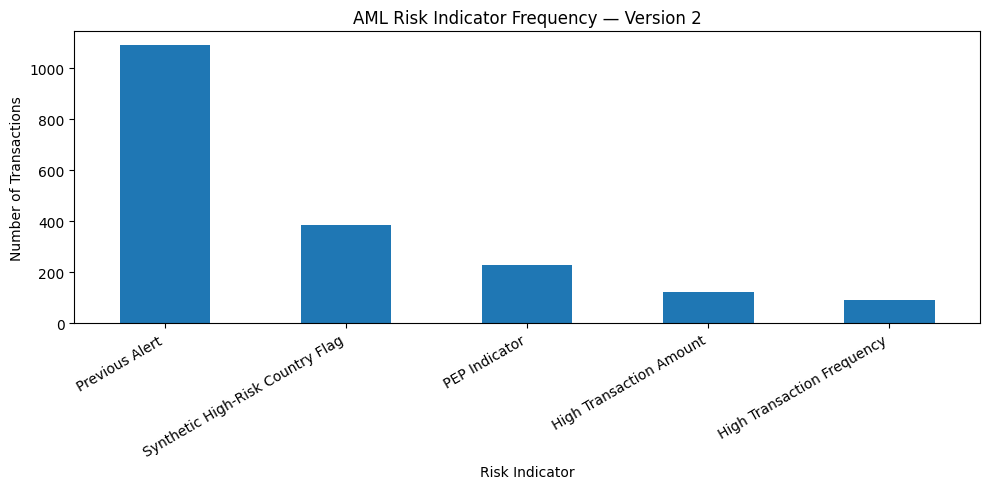

In [36]:
# Step 27: Analyze Risk Indicator Frequency

risk_indicator_counts = pd.Series({
    "High Transaction Amount": data["High_Amount_Flag"].sum(),
    "High Transaction Frequency": data["High_Frequency_Flag"].sum(),
    "PEP Indicator": data["PEP_Flag"].sum(),
    "Synthetic High-Risk Country Flag": data["High_Risk_Country"].sum(),
    "Previous Alert": data["Previous_Alert_Flag"].sum()
}).sort_values(ascending=False)

print("AML Risk Indicator Frequency")
display(risk_indicator_counts)

# Visualize indicator frequency
plt.figure(figsize=(10, 5))

risk_indicator_counts.plot(kind="bar")

plt.title("AML Risk Indicator Frequency — Version 2")
plt.xlabel("Risk Indicator")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [37]:
# Step 28: Create Customer-Level AML Risk Summary

customer_summary = data.groupby("Customer_ID").agg(
    Total_Transactions=("Transaction_ID", "count"),
    Total_Transaction_Value=("Transaction_Amount", "sum"),
    Average_Transaction_Amount=("Transaction_Amount", "mean"),
    Maximum_Transaction_Amount=("Transaction_Amount", "max"),
    Maximum_Risk_Score=("Risk_Score", "max"),
    Total_PEP_Flags=("PEP_Flag", "sum"),
    Total_High_Risk_Country_Flags=("High_Risk_Country", "sum"),
    Total_High_Amount_Flags=("High_Amount_Flag", "sum"),
    Total_High_Frequency_Flags=("High_Frequency_Flag", "sum"),
    Total_Previous_Alert_Flags=("Previous_Alert_Flag", "sum")
).reset_index()

customer_summary = customer_summary.sort_values(
    by="Maximum_Risk_Score",
    ascending=False
)

print("Customer-Level AML Risk Summary")
print("Unique customers:", len(customer_summary))

display(customer_summary.head(20))

Customer-Level AML Risk Summary
Unique customers: 989


,Customer_ID,Total_Transactions,Total_Transaction_Value,Average_Transaction_Amount,Maximum_Transaction_Amount,Maximum_Risk_Score,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_High_Amount_Flags,Total_High_Frequency_Flags,Total_Previous_Alert_Flags
527,CUST1532,9,16022.72,1780.302222,5269.09,65,1,1,0,1,2
576,CUST1583,5,4529.72,905.944000,1585.90,65,2,1,0,1,0
526,CUST1531,5,24133.34,4826.668000,11513.17,65,0,1,1,1,0
764,CUST1773,2,14828.61,7414.305000,10119.55,60,1,0,1,0,1
266,CUST1270,5,16207.39,3241.478000,11008.34,60,1,1,1,0,2
594,CUST1601,5,16279.53,3255.906000,10782.46,60,1,0,1,0,2
672,CUST1680,7,26836.42,3833.774286,16343.47,55,0,0,1,1,2
878,CUST1888,7,25624.95,3660.707143,14848.24,55,1,2,1,0,2
232,CUST1236,9,29172.17,3241.352222,11574.80,55,1,2,1,0,3
486,CUST1491,5,20856.77,4171.354000,14852.84,50,1,0,1,0,1


In [38]:

# Step 29: Calculate Customer-Level AML Risk Score

# Count each customer's High or Critical transactions
high_risk_transaction_counts = (
    data[data["Risk_Category"].isin(["High", "Critical"])]
    .groupby("Customer_ID")
    .size()
    .rename("High_Risk_Transaction_Count")
)

customer_summary = customer_summary.merge(
    high_risk_transaction_counts,
    on="Customer_ID",
    how="left"
)

customer_summary["High_Risk_Transaction_Count"] = (
    customer_summary["High_Risk_Transaction_Count"]
    .fillna(0)
    .astype(int)
)

# Combine maximum transaction score with a capped repeat-alert contribution
customer_summary["Customer_Risk_Score"] = (
    customer_summary["Maximum_Risk_Score"]
    + customer_summary["High_Risk_Transaction_Count"].clip(upper=3) * 5
).clip(upper=100)

# Assign customer-level risk categories
def classify_customer_risk(score):
    if score >= 75:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 25:
        return "Medium"
    else:
        return "Low"

customer_summary["Customer_Risk_Category"] = (
    customer_summary["Customer_Risk_Score"]
    .apply(classify_customer_risk)
)

customer_summary = customer_summary.sort_values(
    by="Customer_Risk_Score",
    ascending=False
).reset_index(drop=True)

print("Customer-level risk scoring completed.")
print("\nCustomer risk category distribution:")
print(
    customer_summary["Customer_Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
)

display(
    customer_summary[
        [
            "Customer_ID",
            "Total_Transactions",
            "Maximum_Risk_Score",
            "High_Risk_Transaction_Count",
            "Customer_Risk_Score",
            "Customer_Risk_Category"
        ]
    ].head(20)
)


Customer-level risk scoring completed.

Customer risk category distribution:
Customer_Risk_Category
Low         624
Medium      349
High         16
Critical      0
Name: count, dtype: int64


,Customer_ID,Total_Transactions,Maximum_Risk_Score,High_Risk_Transaction_Count,Customer_Risk_Score,Customer_Risk_Category
0,CUST1532,9,65,1,70,High
1,CUST1583,5,65,1,70,High
2,CUST1531,5,65,1,70,High
3,CUST1773,2,60,1,65,High
4,CUST1270,5,60,1,65,High
5,CUST1601,5,60,1,65,High
6,CUST1680,7,55,1,60,High
7,CUST1888,7,55,1,60,High
8,CUST1236,9,55,1,60,High
9,CUST1491,5,50,1,55,High


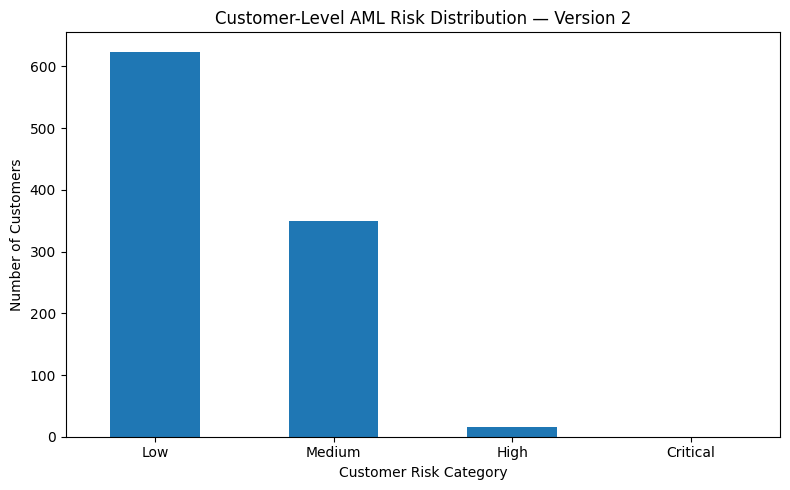

Customer risk distribution:
Customer_Risk_Category
Low         624
Medium      349
High         16
Critical      0
Name: count, dtype: int64


In [39]:

# Step 30: Visualise Customer-Level Risk Distribution

customer_risk_distribution = (
    customer_summary["Customer_Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
)

plt.figure(figsize=(8, 5))
customer_risk_distribution.plot(kind="bar")

plt.title("Customer-Level AML Risk Distribution — Version 2")
plt.xlabel("Customer Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Customer risk distribution:")
print(customer_risk_distribution)


In [40]:

# Step 31: Create a High-Risk Customer Review List

high_risk_customers = customer_summary[
    customer_summary["Customer_Risk_Category"].isin(["High", "Critical"])
].copy()

high_risk_customers = high_risk_customers.sort_values(
    by=["Customer_Risk_Score", "High_Risk_Transaction_Count"],
    ascending=[False, False]
)

review_columns = [
    "Customer_ID",
    "Total_Transactions",
    "Total_Transaction_Value",
    "Maximum_Transaction_Amount",
    "Maximum_Risk_Score",
    "High_Risk_Transaction_Count",
    "Total_PEP_Flags",
    "Total_High_Risk_Country_Flags",
    "Total_Previous_Alert_Flags",
    "Customer_Risk_Score",
    "Customer_Risk_Category"
]

print("High-priority customer review list")
print("Customers requiring review under this prototype:", len(high_risk_customers))

display(high_risk_customers[review_columns])


High-priority customer review list
Customers requiring review under this prototype: 16


,Customer_ID,Total_Transactions,Total_Transaction_Value,Maximum_Transaction_Amount,Maximum_Risk_Score,High_Risk_Transaction_Count,Total_PEP_Flags,Total_High_Risk_Country_Flags,Total_Previous_Alert_Flags,Customer_Risk_Score,Customer_Risk_Category
0,CUST1532,9,16022.72,5269.09,65,1,1,1,2,70,High
1,CUST1583,5,4529.72,1585.90,65,1,2,1,0,70,High
2,CUST1531,5,24133.34,11513.17,65,1,0,1,0,70,High
3,CUST1773,2,14828.61,10119.55,60,1,1,0,1,65,High
4,CUST1270,5,16207.39,11008.34,60,1,1,1,2,65,High
5,CUST1601,5,16279.53,10782.46,60,1,1,0,2,65,High
6,CUST1680,7,26836.42,16343.47,55,1,0,0,2,60,High
7,CUST1888,7,25624.95,14848.24,55,1,1,2,2,60,High
8,CUST1236,9,29172.17,11574.80,55,1,1,2,3,60,High
9,CUST1491,5,20856.77,14852.84,50,1,1,0,1,55,High


In [41]:

# Step 32: Retrieve Transactions for High-Risk Customers

high_risk_customer_ids = high_risk_customers["Customer_ID"].unique()

high_risk_customer_transactions = data[
    data["Customer_ID"].isin(high_risk_customer_ids)
].copy()

high_risk_customer_transactions = high_risk_customer_transactions.sort_values(
    by=["Customer_ID", "Risk_Score", "Transaction_Amount"],
    ascending=[True, False, False]
)

transaction_review_columns = [
    "Transaction_ID",
    "Customer_ID",
    "Customer_Country",
    "Transaction_Type",
    "Transaction_Amount",
    "Transactions_Last_24h",
    "PEP_Flag",
    "High_Risk_Country",
    "Previous_Alerts",
    "Risk_Score",
    "Risk_Category",
    "Alert_Reasons"
]

print("Transaction-level review for high-risk customers")
print("High-risk customers:", len(high_risk_customer_ids))
print("Transactions associated with these customers:",
      len(high_risk_customer_transactions))

display(
    high_risk_customer_transactions[transaction_review_columns].head(30)
)


Transaction-level review for high-risk customers
High-risk customers: 16
Transactions associated with these customers: 85


,Transaction_ID,Customer_ID,Customer_Country,Transaction_Type,Transaction_Amount,Transactions_Last_24h,PEP_Flag,High_Risk_Country,Previous_Alerts,Risk_Score,Risk_Category,Alert_Reasons
3907,TXN003908,CUST1020,UAE,Card Payment,1354.78,16,0,1,1,50,High,Synthetic High-Risk Country Flag | High Transa...
2295,TXN002296,CUST1020,UAE,Bank Transfer,2072.69,19,0,0,0,20,Low,High Transaction Frequency
4955,TXN004956,CUST1020,UAE,Cash Withdrawal,626.09,23,0,0,0,20,Low,High Transaction Frequency
55,TXN000056,CUST1020,UAE,Cash Deposit,744.91,15,0,0,0,0,Low,No risk indicators triggered
2726,TXN002727,CUST1076,Poland,Cash Deposit,43380.63,1,1,0,0,50,High,PEP Indicator | High Transaction Amount
4310,TXN004311,CUST1076,Poland,Card Payment,880.36,1,0,1,0,20,Low,Synthetic High-Risk Country Flag
839,TXN000840,CUST1076,Poland,Bank Transfer,2243.52,2,0,0,0,0,Low,No risk indicators triggered
4076,TXN004077,CUST1236,UK,Bank Transfer,4780.38,6,1,1,1,55,High,PEP Indicator | Synthetic High-Risk Country Fl...
3668,TXN003669,CUST1236,Germany,Bank Transfer,11574.80,3,0,0,0,25,Medium,High Transaction Amount
3271,TXN003272,CUST1236,Germany,Bank Transfer,1604.17,5,0,1,0,20,Low,Synthetic High-Risk Country Flag


In [42]:

# Step 33: Summarise Transactions Linked to High-Risk Customers

print("Risk category breakdown:")
print(
    high_risk_customer_transactions["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
)

print("\nTransaction type breakdown:")
print(
    high_risk_customer_transactions["Transaction_Type"]
    .value_counts()
)

print("\nTotal transaction value:")
print(
    round(
        high_risk_customer_transactions["Transaction_Amount"].sum(),
        2
    )
)

print("\nAverage transaction amount:")
print(
    round(
        high_risk_customer_transactions["Transaction_Amount"].mean(),
        2
    )
)



Risk category breakdown:
Risk_Category
Low         64
Medium       5
High        16
Critical     0
Name: count, dtype: int64

Transaction type breakdown:
Transaction_Type
Bank Transfer      36
Card Payment       32
Cash Deposit       10
Cash Withdrawal     7
Name: count, dtype: int64

Total transaction value:
327979.11

Average transaction amount:
3858.58


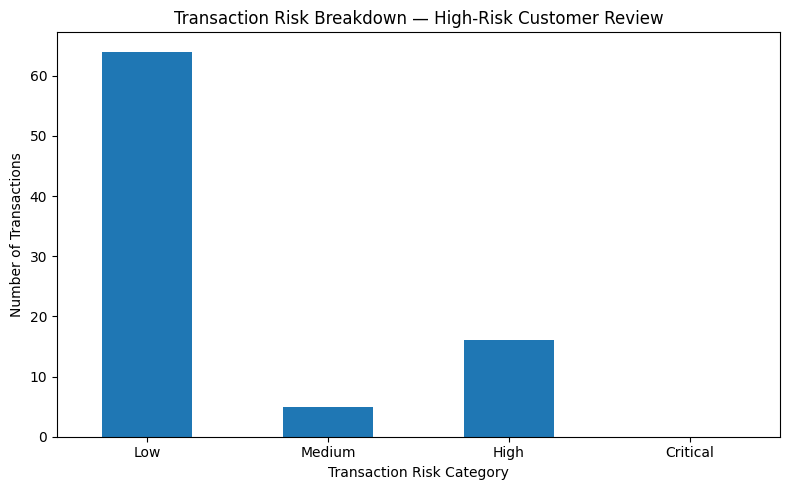

Transactions by risk category:
Risk_Category
Low         64
Medium       5
High        16
Critical     0
Name: count, dtype: int64


In [43]:

# Step 34: Plot Risk Categories for Transactions Under Review

transaction_risk_counts = (
    high_risk_customer_transactions["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
)

plt.figure(figsize=(8, 5))
transaction_risk_counts.plot(kind="bar")

plt.title("Transaction Risk Breakdown — High-Risk Customer Review")
plt.xlabel("Transaction Risk Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Transactions by risk category:")
print(transaction_risk_counts)


In [44]:

# Step 35: Generate AML Project Summary Metrics

print("=" * 50)
print("AML TRANSACTION RISK SCORING SYSTEM — VERSION 2")
print("=" * 50)

print("\nDATASET")
print("Total transactions:", len(data))
print("Unique customers:", data["Customer_ID"].nunique())

print("\nTRANSACTION RISK DISTRIBUTION")
print(
    data["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
    .to_string()
)

print("\nTRANSACTION ALERTS")
print("High/Critical transactions:", len(alert_queue))

print("\nCUSTOMER RISK DISTRIBUTION")
print(
    customer_summary["Customer_Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High", "Critical"], fill_value=0)
    .to_string()
)

print("\nCUSTOMER REVIEW")
print("High/Critical customers:", len(high_risk_customers))
print("Transactions linked to these customers:",
      len(high_risk_customer_transactions))

print("\nTRANSACTIONS LINKED TO HIGH-RISK CUSTOMERS")
print("Combined transaction value:",
      round(high_risk_customer_transactions["Transaction_Amount"].sum(), 2))
print("Average transaction amount:",
      round(high_risk_customer_transactions["Transaction_Amount"].mean(), 2))

print("\nNOTE")
print("All records are synthetic. Scores indicate review priority,")
print("not confirmed money laundering or validated model performance.")
print("=" * 50)


AML TRANSACTION RISK SCORING SYSTEM — VERSION 2

DATASET
Total transactions: 5000
Unique customers: 989

TRANSACTION RISK DISTRIBUTION
Risk_Category
Low         4556
Medium       428
High          16
Critical       0

TRANSACTION ALERTS
High/Critical transactions: 16

CUSTOMER RISK DISTRIBUTION
Customer_Risk_Category
Low         624
Medium      349
High         16
Critical      0

CUSTOMER REVIEW
High/Critical customers: 16
Transactions linked to these customers: 85

TRANSACTIONS LINKED TO HIGH-RISK CUSTOMERS
Combined transaction value: 327979.11
Average transaction amount: 3858.58

NOTE
All records are synthetic. Scores indicate review priority,
not confirmed money laundering or validated model performance.


In [45]:

# Step 36: Export AML Project Results

data.to_csv("aml_transactions_v2.csv", index=False)

customer_summary.to_csv(
    "aml_customer_risk_summary_v2.csv",
    index=False
)

alert_queue.to_csv(
    "aml_transaction_alert_queue_v2.csv",
    index=False
)

high_risk_customers.to_csv(
    "aml_high_risk_customer_review_v2.csv",
    index=False
)

high_risk_customer_transactions.to_csv(
    "aml_high_risk_customer_transactions_v2.csv",
    index=False
)

print("Export completed successfully!")
print("Files created:")
print("1. aml_transactions_v2.csv")
print("2. aml_customer_risk_summary_v2.csv")
print("3. aml_transaction_alert_queue_v2.csv")
print("4. aml_high_risk_customer_review_v2.csv")
print("5. aml_high_risk_customer_transactions_v2.csv")


Export completed successfully!
Files created:
1. aml_transactions_v2.csv
2. aml_customer_risk_summary_v2.csv
3. aml_transaction_alert_queue_v2.csv
4. aml_high_risk_customer_review_v2.csv
5. aml_high_risk_customer_transactions_v2.csv


In [46]:

import os

print("Current folder:", os.getcwd())
print("\nCSV files available:")

for filename in os.listdir():
    if filename.endswith(".csv"):
        print(filename)


Current folder: /content

CSV files available:
aml_transaction_alert_queue_v2.csv
aml_transactions_v2.csv
aml_high_risk_customer_transactions_v2.csv
aml_high_risk_customer_review_v2.csv
aml_customer_risk_summary_v2.csv
